# Bankruptcy prediction

**Question:** Can we use fewer financial variables and still build a useful decision tree?

We want to help an analyst choose which companies need a closer review.
The target is `Bankrupt?`: 1 means bankruptcy and 0 means no bankruptcy.

Our steps:
1. Load and check the data.
2. Explore the training data and correlations.
3. Select variables with L1 regularization.
4. Compare decision trees and evaluate the final model.

Source: [UCI Taiwanese Bankruptcy Prediction](https://archive.ics.uci.edu/dataset/572/taiwanese+bankruptcy+prediction).
The source describes data collected in Taiwan between 1999 and 2009.

## 1. Imports
Run the cells in order. Keep `data.csv` in the same folder as this notebook. The packages are listed in `requirements.txt`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import VarianceThreshold, SelectFromModel
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    average_precision_score, precision_score, recall_score,
    accuracy_score, ConfusionMatrixDisplay
)

In [2]:
random_state = 42
plt.rcParams["figure.figsize"] = (8, 4)

## 2. Load and check the data

In [3]:
data = pd.read_csv("data.csv")
data.columns = data.columns.str.strip()
data.head()

,Bankrupt?,ROA(C) before interest and depreciation before interest,ROA(A) before interest and % after tax,ROA(B) before interest and depreciation after tax,Operating Gross Margin,Realized Sales Gross Margin,Operating Profit Rate,Pre-tax net Interest Rate,After-tax net Interest Rate,Non-industry income and expenditure/revenue,...,Net Income to Total Assets,Total assets to GNP price,No-credit Interval,Gross Profit to Sales,Net Income to Stockholder's Equity,Liability to Equity,Degree of Financial Leverage (DFL),Interest Coverage Ratio (Interest expense to EBIT),Net Income Flag,Equity to Liability
0,1,0.370594,0.424389,0.405750,0.601457,0.601457,0.998969,0.796887,0.808809,0.302646,...,0.716845,0.009219,0.622879,0.601453,0.827890,0.290202,0.026601,0.564050,1,0.016469
1,1,0.464291,0.538214,0.516730,0.610235,0.610235,0.998946,0.797380,0.809301,0.303556,...,0.795297,0.008323,0.623652,0.610237,0.839969,0.283846,0.264577,0.570175,1,0.020794
2,1,0.426071,0.499019,0.472295,0.601450,0.601364,0.998857,0.796403,0.808388,0.302035,...,0.774670,0.040003,0.623841,0.601449,0.836774,0.290189,0.026555,0.563706,1,0.016474
3,1,0.399844,0.451265,0.457733,0.583541,0.583541,0.998700,0.796967,0.808966,0.303350,...,0.739555,0.003252,0.622929,0.583538,0.834697,0.281721,0.026697,0.564663,1,0.023982
4,1,0.465022,0.538432,0.522298,0.598783,0.598783,0.998973,0.797366,0.809304,0.303475,...,0.795016,0.003878,0.623521,0.598782,0.839973,0.278514,0.024752,0.575617,1,0.035490


In [4]:
print("Rows:", data.shape[0])
print("Predictors:", data.shape[1] - 1)

Rows: 6819
Predictors: 95


In [5]:
checks = pd.Series({
    "Missing values": data.isna().sum().sum(),
    "Infinite values": np.isinf(data.to_numpy()).sum(),
    "Duplicate rows": data.duplicated().sum()
})
checks

Missing values     0
Infinite values    0
Duplicate rows     0
dtype: int64

In [6]:
target_counts = data["Bankrupt?"].value_counts().sort_index()
pd.DataFrame({
    "Count": target_counts,
    "Percentage": 100 * target_counts / len(data)
})

,Count,Percentage
Bankrupt?,,
0,6599,96.77372
1,220,3.22628


Only 3.23% of observations are bankrupt. Always predicting 0 gives high accuracy but detects no bankruptcies.

Our main score is **average precision (AP)**: it measures how well the model ranks bankrupt companies. Higher is better.
Precision measures how many alerts are correct. Recall measures how many bankruptcies we detect.

## 3. Keep a separate test set
We use 80% for training and 20% for testing. `stratify` keeps similar class proportions. From this point, exploration uses the training set. We use the test set only at the end.

In [7]:
X = data.drop(columns="Bankrupt?")
y = data["Bankrupt?"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=random_state
)

## 4. Correlation
We plot the ten predictors most correlated with bankruptcy in the training set.
Pearson correlation measures linear relationships. It does not prove causation and can miss nonlinear patterns.

In [8]:
correlations = X_train.corrwith(y_train).dropna()
top_names = correlations.abs().sort_values(ascending=False).head(10).index

/Users/william/.pyenv/versions/3.13.11/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3036: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/Users/william/.pyenv/versions/3.13.11/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


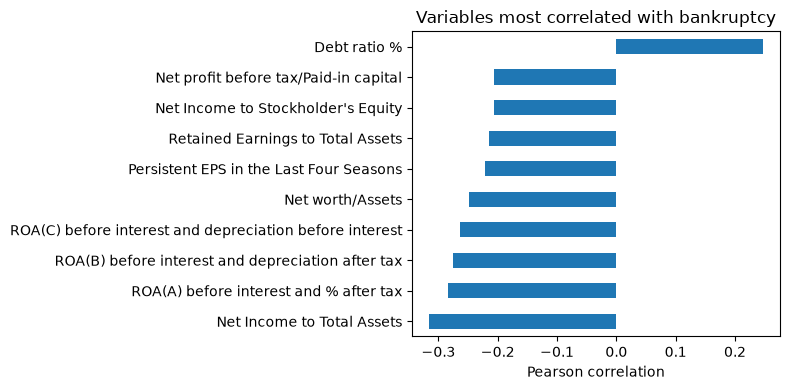

In [9]:
correlations.loc[top_names].sort_values().plot.barh()
plt.xlabel("Pearson correlation")
plt.title("Variables most correlated with bankruptcy")
plt.tight_layout()
plt.show()

## 5. Validation and model settings

We use 5-fold stratified cross-validation on the training set.
Each pipeline learns its preprocessing and selection only from the training part of each fold.

We try a small number of settings:
- Tree depth: 3 or 5.
- Minimum observations per leaf: 10 or 30.
- `class_weight="balanced"` gives more weight to the rare bankruptcy class.

We choose settings using average precision. The test set is not used for tuning.

In [10]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=random_state)

tree_grid = {
    "tree__max_depth": [3, 5],
    "tree__min_samples_leaf": [10, 30]
}

## 6. Decision tree without variable selection
This model is our reference for measuring the value of selection. It only removes constant columns.

In [11]:
tree_pipeline = Pipeline([
    ("constant", VarianceThreshold()),
    ("tree", DecisionTreeClassifier(
        class_weight="balanced", random_state=random_state
    ))
])

In [12]:
tree_search = GridSearchCV(
    tree_pipeline, tree_grid, scoring="average_precision", cv=cv
)
tree_search.fit(X_train, y_train)

print("Best settings:", tree_search.best_params_)
print("Validation AP:", round(tree_search.best_score_, 3))

Best settings: {'tree__max_depth': 5, 'tree__min_samples_leaf': 30}
Validation AP: 0.245


## 7. LASSO-style selection

Our target is binary, so we use **logistic regression with an L1 penalty** rather than ordinary LASSO regression.
L1 makes some coefficients zero. We keep the other variables and train a decision tree on them.

`StandardScaler` puts variables on comparable scales before L1 selection.
A smaller `C` means a stronger penalty. We try 0.01, 0.1 and 1.
Scaling and selection are fitted inside each training fold.

In [13]:
l1_model = LogisticRegression(
    l1_ratio=1,
    solver="liblinear",
    class_weight="balanced",
    max_iter=2000,
    random_state=random_state
)

selected_pipeline = Pipeline([
    ("constant", VarianceThreshold()),
    ("scale", StandardScaler()),
    ("selection", SelectFromModel(l1_model, threshold=0.00001)),
    ("tree", DecisionTreeClassifier(
        class_weight="balanced", random_state=random_state
    ))
])

In [14]:
selection_grid = {
    "selection__estimator__C": [0.01, 0.1, 1],
    "tree__max_depth": [3, 5],
    "tree__min_samples_leaf": [10, 30]
}

selection_search = GridSearchCV(
    selected_pipeline, selection_grid, scoring="average_precision", cv=cv
)
selection_search.fit(X_train, y_train)

print("Best settings:", selection_search.best_params_)
print("Validation AP:", round(selection_search.best_score_, 3))

Best settings: {'selection__estimator__C': 0.01, 'tree__max_depth': 5, 'tree__min_samples_leaf': 30}
Validation AP: 0.276


## 8. Selected variables
After choosing settings, `GridSearchCV` fits the best pipeline on the full training set. The following variables come from that fitted pipeline.

In [15]:
selected_model = selection_search.best_estimator_
variable_names = X_train.columns[
    selected_model.named_steps["constant"].get_support()
]
selector = selected_model.named_steps["selection"]
selected_names = variable_names[selector.get_support()]

print("Original variables:", X_train.shape[1])
print("Selected variables:", len(selected_names))

Original variables: 95
Selected variables: 17


In [16]:
pd.Series(selected_names, name="Selected variables")

0     ROA(C) before interest and depreciation before...
1     ROA(B) before interest and depreciation after tax
2                               Net Value Per Share (B)
3               Persistent EPS in the Last Four Seasons
4               Realized Sales Gross Profit Growth Rate
5                            Total debt/Total net worth
6                                          Debt ratio %
7                                      Net worth/Assets
8                                  Total Asset Turnover
9                       Fixed Assets Turnover Frequency
10                      Net Worth Turnover Rate (times)
11                      Working Capital to Total Assets
12                               Cash/Current Liability
13                                   Cash Turnover Rate
14                               Fixed Assets to Assets
15                               Cash Flow to Liability
16                           Net Income to Total Assets
Name: Selected variables, dtype: str

## 9. Choose the model before looking at the test results
We recommend the model with the higher mean validation AP. We still report both trees to show whether selection helped.

In [17]:
if selection_search.best_score_ >= tree_search.best_score_:
    final_name = "L1 selection + tree"
    final_model = selection_search.best_estimator_
else:
    final_name = "Tree without selection"
    final_model = tree_search.best_estimator_

print("Model chosen using validation:", final_name)

Model chosen using validation: L1 selection + tree


## 10. Final test results
The baseline always predicts the most common class.
AP uses probability scores. Precision, recall and accuracy use the default class predictions.

In [18]:
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)

models = {
    "Majority baseline": baseline,
    "Tree without selection": tree_search.best_estimator_,
    "L1 selection + tree": selection_search.best_estimator_
}

In [19]:
results = []

for name, model in models.items():
    prediction = model.predict(X_test)
    probability = model.predict_proba(X_test)[:, 1]
    results.append({
        "Model": name,
        "Average precision": average_precision_score(y_test, probability),
        "Recall": recall_score(y_test, prediction, zero_division=0),
        "Precision": precision_score(y_test, prediction, zero_division=0),
        "Accuracy": accuracy_score(y_test, prediction)
    })

test_results = pd.DataFrame(results).set_index("Model")
test_results.round(3)

,Average precision,Recall,Precision,Accuracy
Model,,,,
Majority baseline,0.032,0.000,0.000,0.968
Tree without selection,0.260,0.818,0.185,0.878
L1 selection + tree,0.271,0.773,0.158,0.860


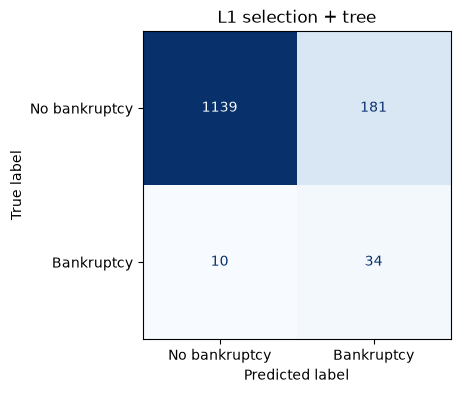

In [20]:
final_prediction = final_model.predict(X_test)

ConfusionMatrixDisplay.from_predictions(
    y_test, final_prediction,
    display_labels=["No bankruptcy", "Bankruptcy"],
    cmap="Blues", colorbar=False
)
plt.title(final_name)
plt.show()

## 11. Understand the combined model
We show the first three levels of the tree after L1 selection. Some branches may continue below the displayed levels. Thresholds use standardized values because this tree follows the scaler.

Because we use balanced class weights, the `value` proportions in the tree are weighted class proportions, not the original class frequencies.

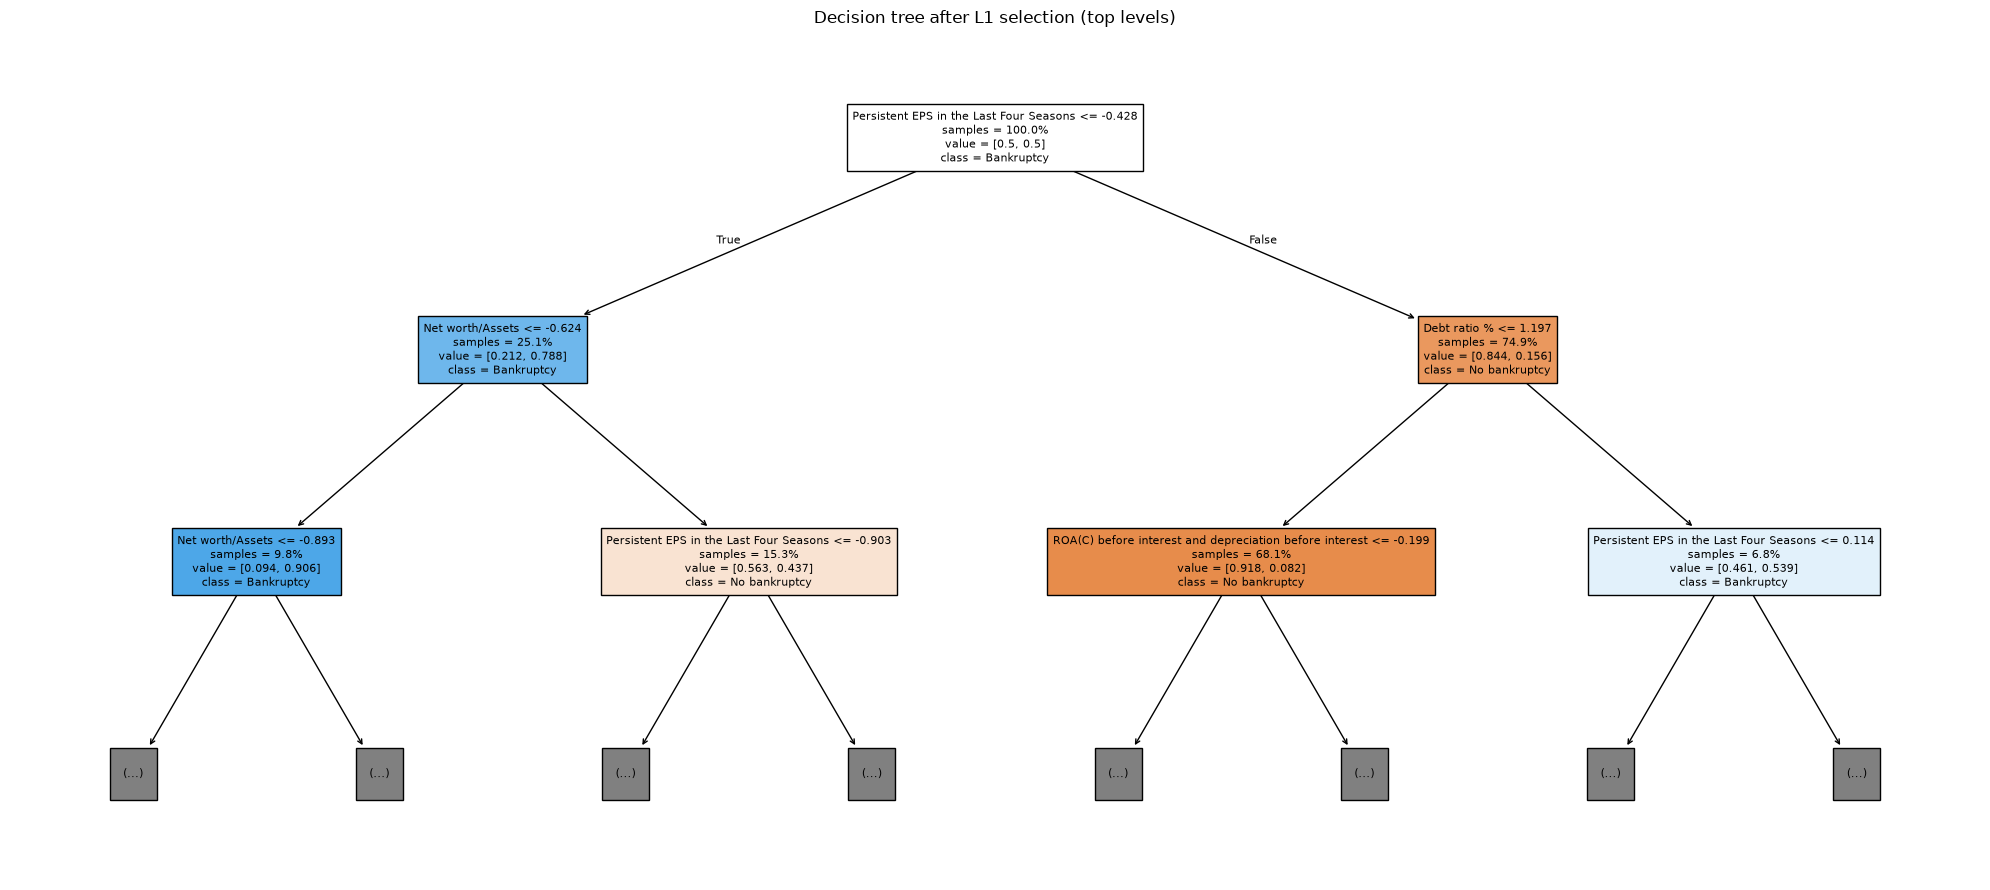

In [21]:
plt.figure(figsize=(20, 9))
plot_tree(
    selected_model.named_steps["tree"],
    feature_names=selected_names.tolist(),
    class_names=["No bankruptcy", "Bankruptcy"],
    max_depth=2,
    filled=True,
    impurity=False,
    proportion=True,
    fontsize=8
)
plt.title("Decision tree after L1 selection (top levels)")
plt.tight_layout()
plt.show()

## 12. Conclusion

L1 kept **17 of 95 variables**. Validation AP increased from **0.245 to 0.276**, so we chose the combined model.

On the test set, AP increased slightly from **0.260 to 0.271**.
The combined model detected **34 of 44 bankrupt companies** but produced **181 false alarms**.
Its recall was **77.3%** and its precision was **15.8%**.

**Selection simplified the model while keeping similar predictive performance.**
The tree without selection had higher test precision and recall at the default threshold.
The combined model is not better on every metric.

The model could help prioritize manual reviews, but most alerts are false alarms.
Results depend on one split and only 220 bankruptcy cases.
These historical Taiwanese data may not represent current companies.
Without dates or company IDs, we cannot test performance on future years or separate repeated companies.

The brief also requires a PDF report and an appendix with all relevant LLM prompts and answers verbatim.